# Ray Train: validation data, run config and results

Two workers train with a train and a validation dataset, a train_loop_config dict and a RunConfig; result nodes pull the final metrics and the run directory out of the Result.

**When to use it.** A realistic training job skeleton: hyperparameters passed in, checkpoints kept under a storage path, metrics read back afterwards.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

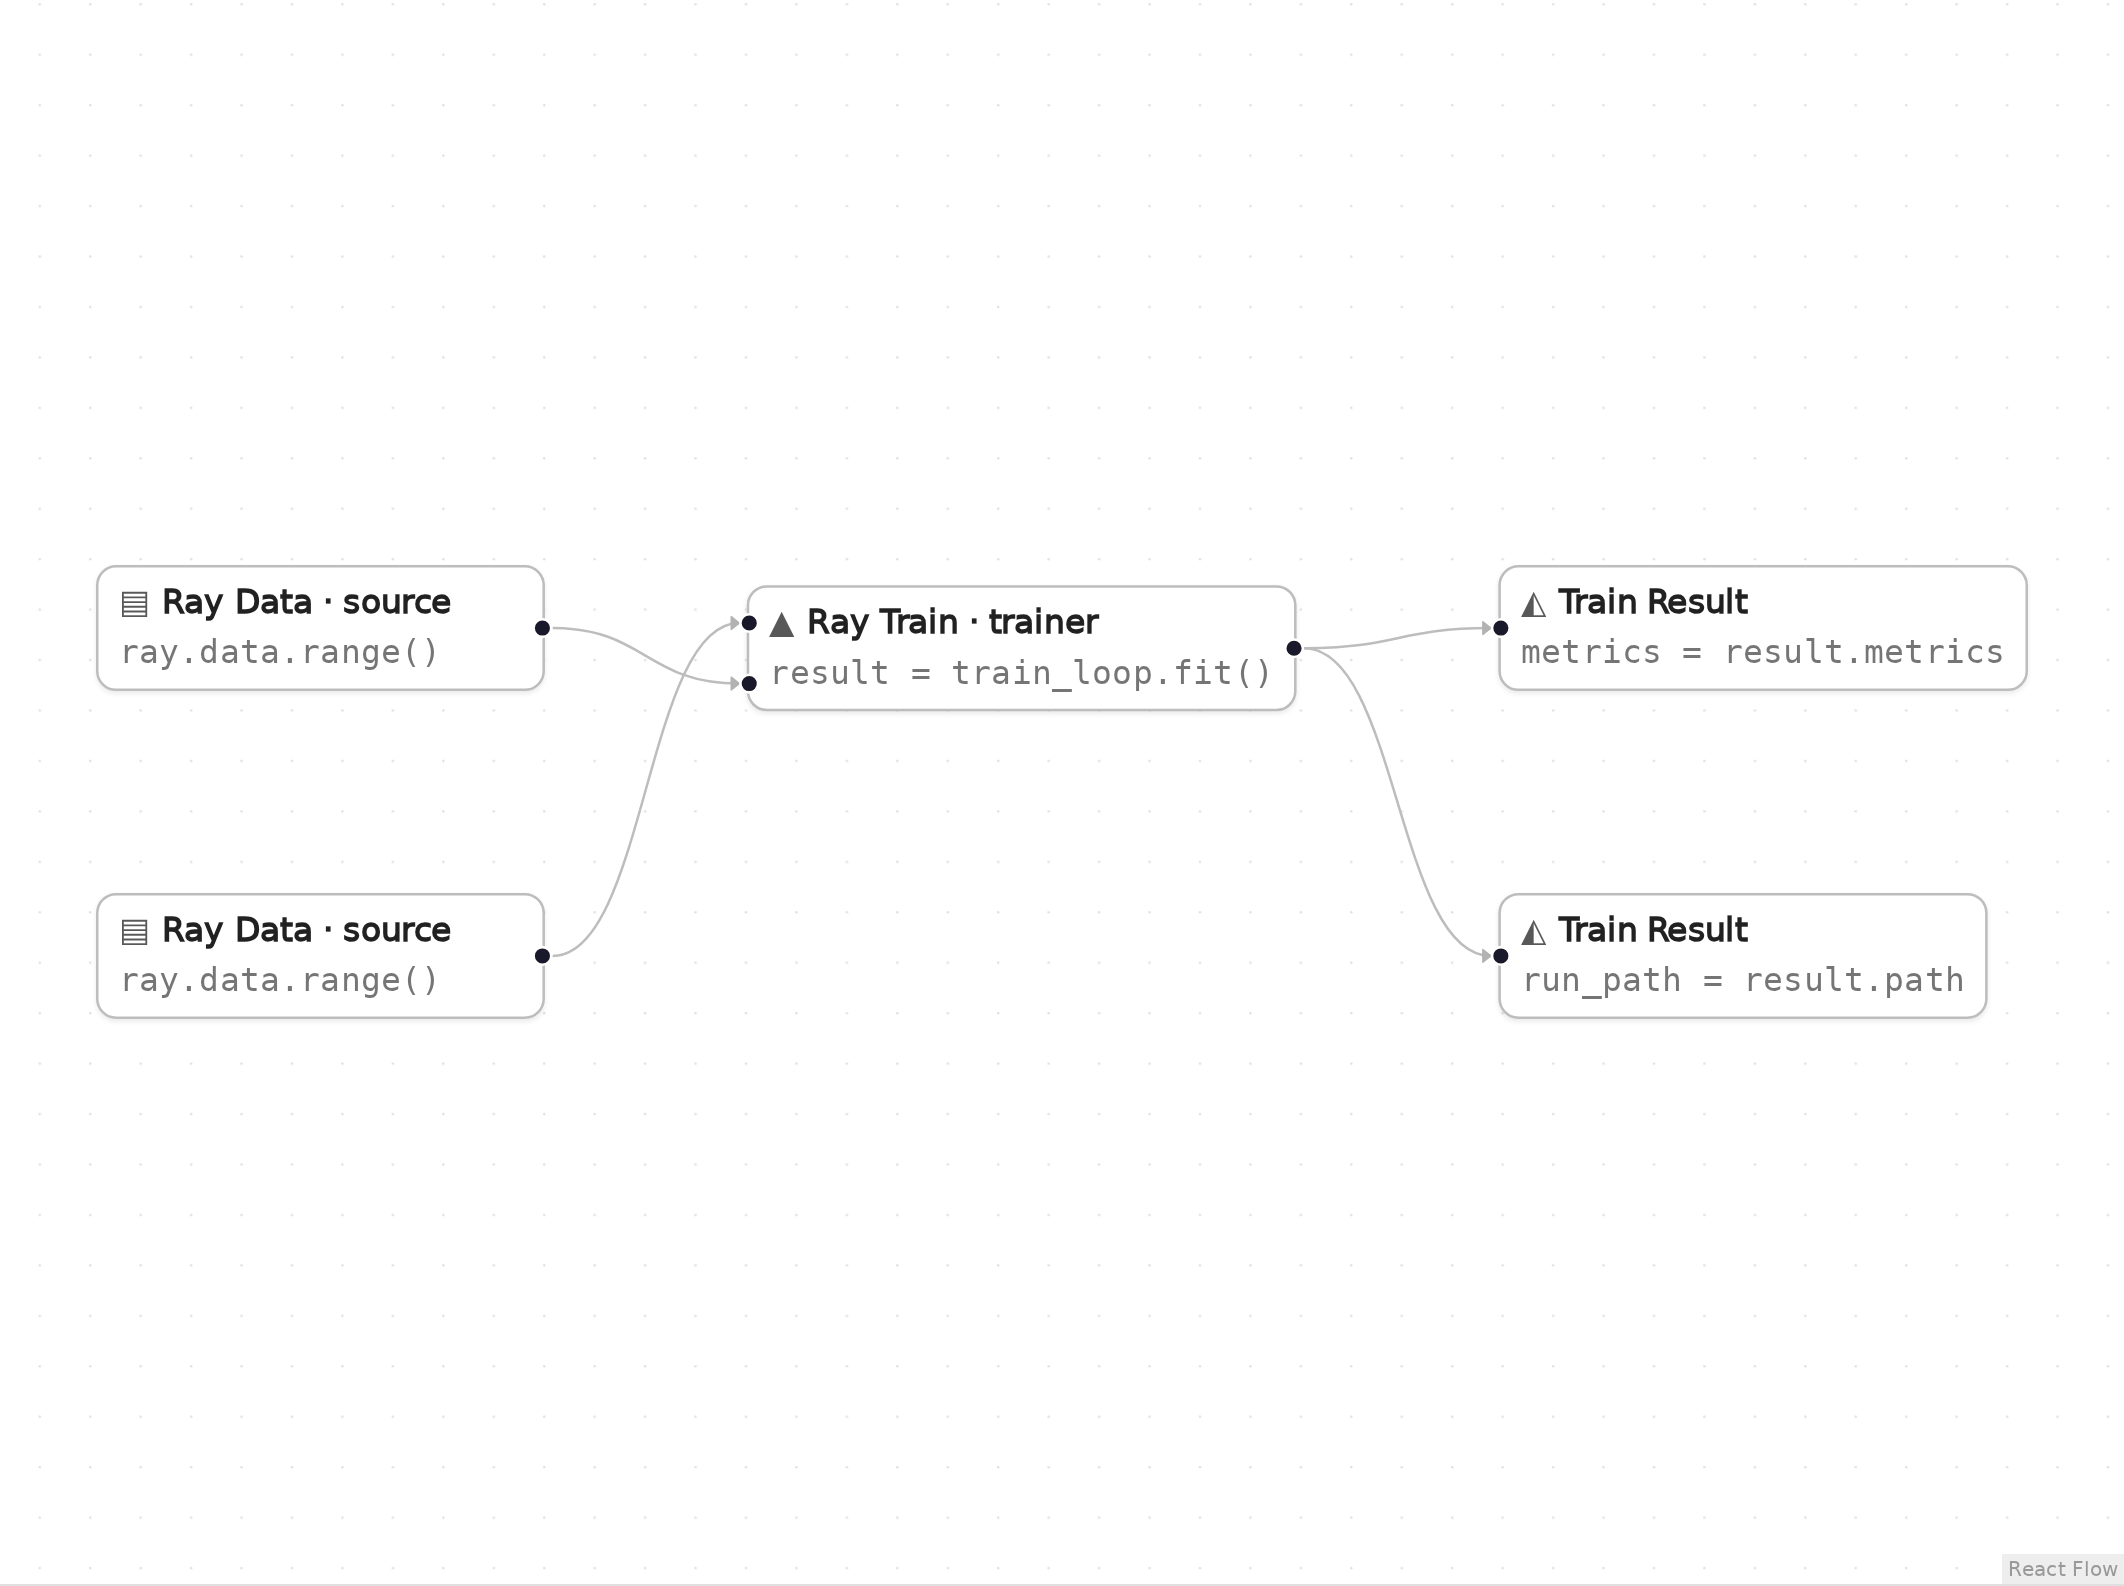

*The graph in Eugo's visual Ray builder.* Both sources show `ray.data.range()`. The upper one is the 80-row training dataset (`n1`, passed as `"train"`) and the lower one is the 20-row validation dataset (`n2`, passed as `"val"`). Their edges cross on the way into the trainer.

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
import json
import os
import tempfile

import ray


def train_loop(config):
    # Runs on each of the two workers; config is the train_loop_config dict.
    train_rows = sum(len(b["id"]) for b in ray.train.get_dataset_shard("train").iter_batches(batch_size=8))
    val_rows = sum(len(b["id"]) for b in ray.train.get_dataset_shard("val").iter_batches(batch_size=8))
    for epoch in range(config["epochs"]):
        metrics = {"epoch": epoch, "lr": config["lr"], "train_rows": train_rows, "val_rows": val_rows}
        with tempfile.TemporaryDirectory() as tmp:
            checkpoint = None
            if ray.train.get_context().get_world_rank() == 0:
                # Only the first worker saves state; every worker still calls report().
                with open(os.path.join(tmp, "state.json"), "w") as f:
                    json.dump(metrics, f)
                checkpoint = ray.train.Checkpoint.from_directory(tmp)
            ray.train.report(metrics, checkpoint=checkpoint)

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

import ray
from ray.train import CheckpointConfig, RunConfig, ScalingConfig
from ray.train.torch import TorchTrainer

if not ray.is_initialized():
    ray.init()

ds_n1 = ray.data.range(80)
ds_n2 = ray.data.range(20)

_trainer_n3 = TorchTrainer(train_loop, train_loop_config={"epochs": 2, "lr": 0.1}, scaling_config=ScalingConfig(num_workers=2, use_gpu=False), run_config=RunConfig(storage_path="/tmp/ray_patterns_train", name="with_validation", checkpoint_config=CheckpointConfig(num_to_keep=1)), datasets={"train": ds_n1, "val": ds_n2})
_result_n3 = _trainer_n3.fit()
metrics = _result_n3.metrics
run_path = _result_n3.path

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
import shutil

assert metrics["epoch"] == 1 and metrics["lr"] == 0.1, metrics
assert run_path.startswith("/tmp/ray_patterns_train"), run_path
print("metrics:", metrics)
print("run directory:", run_path)
shutil.rmtree("/tmp/ray_patterns_train", ignore_errors=True)

metrics: {'epoch': 1, 'lr': 0.1, 'train_rows': 40, 'val_rows': 10}
run directory: /tmp/ray_patterns_train/with_validation


## How the graph maps to the code

Each step names a node in the picture by its label, the lines of the generated cell it produced, and what those lines do. Node ids such as `n1` are not drawn on the canvas. Where the builder names a variable after a node, the id is its suffix (for example `_trainer_n3`).

**Setup** (lines 1, 3–5 and 7–8)

```python
# Generated with Eugo's visual Ray builder
...
import ray
from ray.train import CheckpointConfig, RunConfig, ScalingConfig
from ray.train.torch import TorchTrainer
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Source** (node `n1`, line 10)

```python
ds_n1 = ray.data.range(80)
```

The training dataset (80 rows), split across the two workers.

**Source** (node `n2`, line 11)

```python
ds_n2 = ray.data.range(20)
```

The validation dataset, wired into the trainer's val input; workers read it with get_dataset_shard("val").

**Trainer** (node `n3`, lines 13–14)

```python
_trainer_n3 = TorchTrainer(train_loop, train_loop_config={"epochs": 2, "lr": 0.1}, scaling_config=ScalingConfig(num_workers=2, use_gpu=False), run_config=RunConfig(storage_path="/tmp/ray_patterns_train", name="with_validation", checkpoint_config=CheckpointConfig(num_to_keep=1)), datasets={"train": ds_n1, "val": ds_n2})
_result_n3 = _trainer_n3.fit()
```

train_loop_config is passed to train_loop as config; RunConfig sets the storage path, run name and checkpoint retention.

**Train result** (node `x1`, line 15)

```python
metrics = _result_n3.metrics
```

Result.metrics: the metrics reported with the latest checkpoint.

**Train result** (node `x2`, line 16)

```python
run_path = _result_n3.path
```

Result.path: where this run's files were written.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()